# Household Energy Waste Intelligence

**Dataset:** CEEW – India Residential Energy Survey (IRES 2020)

**Objective:** To analyse Indian household energy access, appliance ownership, electricity expenditure and energy-efficiency indicators using Data Science techniques.

**ETL Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and SQLite.

Importing Required Libraries

In [2]:

# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sqlite3

print("All libraries imported successfully!")

''' What does each library do?
Library	      Purpose
Pandas	      Data loading and manipulation
NumPy	        Numerical calculations
Matplotlib	  Creating graphs
Seaborn	      Statistical visualisation
SQLite3	      Database operations '''


All libraries imported successfully!


' What does each library do?\nLibrary\t      Purpose\nPandas\t      Data loading and manipulation\nNumPy\t        Numerical calculations\nMatplotlib\t  Creating graphs\nSeaborn\t      Statistical visualisation\nSQLite3\t      Database operations '

Step 3 — Extract the dataset from GitHub

In [3]:

# Extracting a sample of the IRES dataset from GitHub

url = "https://raw.githubusercontent.com/prithvee2k4/miniprojectgrp3/main/datasets/CEEW%2520-%2520IRES%2520Data.csv"

# Read only the first 5 rows for initial testing
df_sample = pd.read_csv(url, nrows=5)

print("Dataset sample extracted successfully!")
print("Sample dimensions:", df_sample.shape)

display(df_sample)


Dataset sample extracted successfully!
Sample dimensions: (5, 517)


,hhid,enumerator_id,s_name,state_abbv,s_code,d_name,d_code,village_ward_name,village_ward_census_code,interview_date,...,q610_e_bill_year,q613_picture_bill_yn,interview_length,replacement_details,sw_dist,sw_state,asset_index_1,asset_decile_1,asset_index_2,asset_decile_2
0,343937810,OR_4,Odisha,OR,21,PURI,387,SAINSASASAN,408946,12-02-2019,...,NaN,NaN,31,NaN,3915,16129,-2.964007,1,-2.784152,1
1,3444379112,RJ_8,Rajasthan,RJ,8,BARMER,115,PATON KA BARA,87562,1/18/2020,...,NaN,NaN,46,NaN,5237,11732,-2.964007,1,-2.784152,1
2,344869428,JH_4,Jharkhand,JH,20,LOHARDAGA,356,MASMANOTHAKURGAON,363164,12/16/2019,...,NaN,NaN,38,NaN,969,16097,-2.964007,1,-2.784152,1
3,344393847,HAR_2,Haryana,HR,6,PANCHKULA,69,PANCHKULA (M CL) WARD NO.-0001,800363-1,12-11-2019,...,NaN,NaN,38,NaN,1109,10525,-2.352909,1,-2.784152,1
4,352717410,UP_1,Uttar Pradesh,UP,9,SITAPUR,154,AKAI CHANDUPUR TAPPA,137895,1/31/2020,...,NaN,NaN,34,NaN,8933,24252,-2.374308,1,-2.182223,1


Step 4 — Verify the dataset

In [4]:

# Checking the column names

print("Total columns:", len(df_sample.columns))

print("\nColumn names:")
print(df_sample.columns.tolist())


# This helps us confirm that the correct dataset has been extracted.


Total columns: 517

Column names:
['hhid', 'enumerator_id', 's_name', 'state_abbv', 's_code', 'd_name', 'd_code', 'village_ward_name', 'village_ward_census_code', 'interview_date', 'interview_start_time', 'q103_survey_type', 'q201_resp_gender', 'q202_resp_age', 'q203_priminc_earner_who', 'q203_priminc_earner_who_other_s', 'q204_priminc_earner_gender', 'q205_priminc_earner_age', 'q206_priminc_earner_head_yn', 'q208_priminc_earner_edu', 'q209_edu_highest', 'q210_religion', 'q210_religion_other_s', 'q211_caste', 'q212_ration_card', 'q213_no_members', 'q214_no_members_lessthan18', 'q214_no_members_18_40', 'q214_no_members_41_60', 'q214_no_members_morethan60', 'q215_no_members_studying', 'q216_house_pucca_kachha', 'q217_house_type', 'q218_house_no_stories', 'q219_house_stay_groundfloor_yn', 'q219_house_stay_middlefloor_yn', 'q219_house_stay_topfloor_yn', 'q219_house_stay_allfloors_yn', 'q220_own_house_yn', 'q222_yrs_samehouse', 'q223_house_no_bedrooms', 'q224_house_no_toilets', 'q225_house_

Step 5 — Load the complete IRES dataset

In [5]:

# Extracting the complete IRES dataset

df = pd.read_csv(url, low_memory=False)

print("Complete dataset extracted successfully!")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Complete dataset extracted successfully!
Total rows: 14851
Total columns: 517


Step 6 — Understand the dataset

In [6]:
display(df.head())

,hhid,enumerator_id,s_name,state_abbv,s_code,d_name,d_code,village_ward_name,village_ward_census_code,interview_date,...,q610_e_bill_year,q613_picture_bill_yn,interview_length,replacement_details,sw_dist,sw_state,asset_index_1,asset_decile_1,asset_index_2,asset_decile_2
0,343937810,OR_4,Odisha,OR,21,PURI,387,SAINSASASAN,408946,12-02-2019,...,NaN,NaN,31,NaN,3915.0,16129.0,-2.964007,1,-2.784152,1
1,3444379112,RJ_8,Rajasthan,RJ,8,BARMER,115,PATON KA BARA,87562,1/18/2020,...,NaN,NaN,46,NaN,5237.0,11732.0,-2.964007,1,-2.784152,1
2,344869428,JH_4,Jharkhand,JH,20,LOHARDAGA,356,MASMANOTHAKURGAON,363164,12/16/2019,...,NaN,NaN,38,NaN,969.0,16097.0,-2.964007,1,-2.784152,1
3,344393847,HAR_2,Haryana,HR,6,PANCHKULA,69,PANCHKULA (M CL) WARD NO.-0001,800363-1,12-11-2019,...,NaN,NaN,38,NaN,1109.0,10525.0,-2.352909,1,-2.784152,1
4,352717410,UP_1,Uttar Pradesh,UP,9,SITAPUR,154,AKAI CHANDUPUR TAPPA,137895,1/31/2020,...,NaN,NaN,34,NaN,8933.0,24252.0,-2.374308,1,-2.182223,1


In [7]:
display(df.tail())

,hhid,enumerator_id,s_name,state_abbv,s_code,d_name,d_code,village_ward_name,village_ward_census_code,interview_date,...,q610_e_bill_year,q613_picture_bill_yn,interview_length,replacement_details,sw_dist,sw_state,asset_index_1,asset_decile_1,asset_index_2,asset_decile_2
14846,35484693,HP_5,Himachal Pradesh,HP,2,MANDI,27,SUNDARNAGAR (M CL) WARD NO.-0011,800106-11,02-11-2020,...,NaN,NaN,37,NaN,962.0,1630.00,2.745562,10,2.546635,10
14847,3444563174,UK_4,Uttarakhand,UK,5,NAINITAL,66,HIMMATPUR MALLA,55146,01-05-2020,...,NaN,NaN,28,NaN,2395.0,7415.00,4.565676,10,5.152835,10
14848,3444379117,RJ_8,Rajasthan,RJ,8,BARAN,128,GUL KHERI,103624,1/13/2020,...,2019.0,1.0,43,NaN,2394.0,12261.00,2.715681,10,3.192761,10
14849,344176292,TEL_3,Andhra Pradesh,AP,28,VIZIANAGARAM,543,VIZIANAGARAM (M) WARD NO.-0017,802946-17,12-10-2019,...,2019.0,1.0,27,NaN,3863.0,16474.36,2.965650,10,2.795137,10
14850,344207167,UK_1,Uttarakhand,UK,5,HARDWAR,68,SUNHAIRA (CT) WARD NO.-0001,56632-1,12-08-2019,...,NaN,NaN,32,NaN,2784.0,4879.00,3.555350,10,3.397065,10


In [8]:

# Dataset Overview

# 1. Dataset Shape
print("========== DATASET SHAPE ==========")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


# 2. First Five Records
print("\n========== FIRST FIVE RECORDS ==========")
display(df.head())


# 3. Dataset Information
print("\n========== DATASET INFORMATION ==========")
df.info()


========== DATASET SHAPE ==========
Total Rows: 14851
Total Columns: 517

========== FIRST FIVE RECORDS ==========


,hhid,enumerator_id,s_name,state_abbv,s_code,d_name,d_code,village_ward_name,village_ward_census_code,interview_date,...,q610_e_bill_year,q613_picture_bill_yn,interview_length,replacement_details,sw_dist,sw_state,asset_index_1,asset_decile_1,asset_index_2,asset_decile_2
0,343937810,OR_4,Odisha,OR,21,PURI,387,SAINSASASAN,408946,12-02-2019,...,NaN,NaN,31,NaN,3915.0,16129.0,-2.964007,1,-2.784152,1
1,3444379112,RJ_8,Rajasthan,RJ,8,BARMER,115,PATON KA BARA,87562,1/18/2020,...,NaN,NaN,46,NaN,5237.0,11732.0,-2.964007,1,-2.784152,1
2,344869428,JH_4,Jharkhand,JH,20,LOHARDAGA,356,MASMANOTHAKURGAON,363164,12/16/2019,...,NaN,NaN,38,NaN,969.0,16097.0,-2.964007,1,-2.784152,1
3,344393847,HAR_2,Haryana,HR,6,PANCHKULA,69,PANCHKULA (M CL) WARD NO.-0001,800363-1,12-11-2019,...,NaN,NaN,38,NaN,1109.0,10525.0,-2.352909,1,-2.784152,1
4,352717410,UP_1,Uttar Pradesh,UP,9,SITAPUR,154,AKAI CHANDUPUR TAPPA,137895,1/31/2020,...,NaN,NaN,34,NaN,8933.0,24252.0,-2.374308,1,-2.182223,1



========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14851 entries, 0 to 14850
Columns: 517 entries, hhid to asset_decile_2
dtypes: float64(425), int64(61), object(31)
memory usage: 58.6+ MB


# Data Quality Assessment

Check missing values

In [9]:
# Checking missing values in the dataset

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns containing missing values:",
      (missing_values > 0).sum())

Total missing values: 4027943

Columns containing missing values: 443


Check duplicate records

In [10]:
# Checking duplicate rows

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


Check unique values

In [11]:
# Checking unique values in each column

unique_values = df.nunique()

display(unique_values)

,0
hhid,14851
enumerator_id,224
s_name,21
state_abbv,21
s_code,21
...,...
sw_state,452
asset_index_1,748
asset_decile_1,10
asset_index_2,500


In [12]:

# Categorising columns based on unique values

print("Total columns:", len(df.columns))

print("\nColumns with only 1 unique value:")
display(df.nunique()[df.nunique() == 1])

print("\nColumns with 10 or fewer unique values:")
display(df.nunique()[df.nunique() <= 10])

print("\nColumns with more than 100 unique values:")
display(df.nunique()[df.nunique() > 100])


Total columns: 517

Columns with only 1 unique value:


,0
q434_1_ac_nohighstar_other,1
q442_1_ac_4_cap,1
q442_1_ac_4_hrs,1
q442_1_ac_4_months_no,1
q442_1_ac_4_bee_rating,1
q443_ac_freq_tech_serv_other_s,1
q457_geyser_3_hrs,1
q457_geyser_3_min,1
q458_a_imm_rod_3_hrs,1
q458_a_imm_rod_3_min,1



Columns with 10 or fewer unique values:


,0
q103_survey_type,2
q201_resp_gender,2
q203_priminc_earner_who,6
q203_priminc_earner_who_other_s,8
q204_priminc_earner_gender,2
...,...
q610_elec_bill_physical_yn,2
q610_e_bill_year,7
q613_picture_bill_yn,2
asset_decile_1,10



Columns with more than 100 unique values:


,0
hhid,14851
enumerator_id,224
d_name,151
d_code,152
village_ward_name,1806
village_ward_census_code,1806
interview_date,117
interview_start_time,648
q227_a_plot_area,347
q227_b_plot_area_estmtd,111


Investigate constant columns

In [13]:


# Identifying columns with only one unique value

constant_columns = df.columns[df.nunique() == 1]

constant_analysis = pd.DataFrame({
    "Column_Name": constant_columns,
    "Unique_Value": [
        df[col].dropna().iloc[0]
        for col in constant_columns
    ],
    "Missing_Count": [
        df[col].isnull().sum()
        for col in constant_columns
    ],
    "Missing_Percentage": [
        (df[col].isnull().sum() / len(df)) * 100
        for col in constant_columns
    ]
})

print("Constant columns analysis:")

display(constant_analysis)



Constant columns analysis:


,Column_Name,Unique_Value,Missing_Count,Missing_Percentage
0,q434_1_ac_nohighstar_other,0.0,14646,98.619622
1,q442_1_ac_4_cap,2.0,14850,99.993266
2,q442_1_ac_4_hrs,4.0,14850,99.993266
3,q442_1_ac_4_months_no,3.0,14850,99.993266
4,q442_1_ac_4_bee_rating,5.0,14850,99.993266
5,q443_ac_freq_tech_serv_other_s,NEW AC,14838,99.912464
6,q457_geyser_3_hrs,1.0,14850,99.993266
7,q457_geyser_3_min,0.0,14850,99.993266
8,q458_a_imm_rod_3_hrs,1.0,14849,99.986533
9,q458_a_imm_rod_3_min,0.0,14849,99.986533


Missing-value distribution

In [14]:


# Analysing missing values in all columns

missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

# Sort by highest missing percentage
missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Display top 20 columns
print("Top 20 columns with highest missing values:")

display(missing_analysis.head(20))



Top 20 columns with highest missing values:


,Missing_Count,Missing_Percentage
q316_d_battery_charging_cost,14851,100.000000
q227_b_plot_estmtd_unit_other_s,14851,100.000000
q434_1_ac_nohighstar_other_s,14851,100.000000
q442_1_ac_4_hrs,14850,99.993266
q442_1_ac_4_months_no,14850,99.993266
q442_1_ac_4_cap,14850,99.993266
q442_1_ac_4_bee_rating,14850,99.993266
q457_geyser_3_hrs,14850,99.993266
q457_geyser_3_min,14850,99.993266
q403_bee_benefits_other_s,14849,99.986533


Visualise the missing values

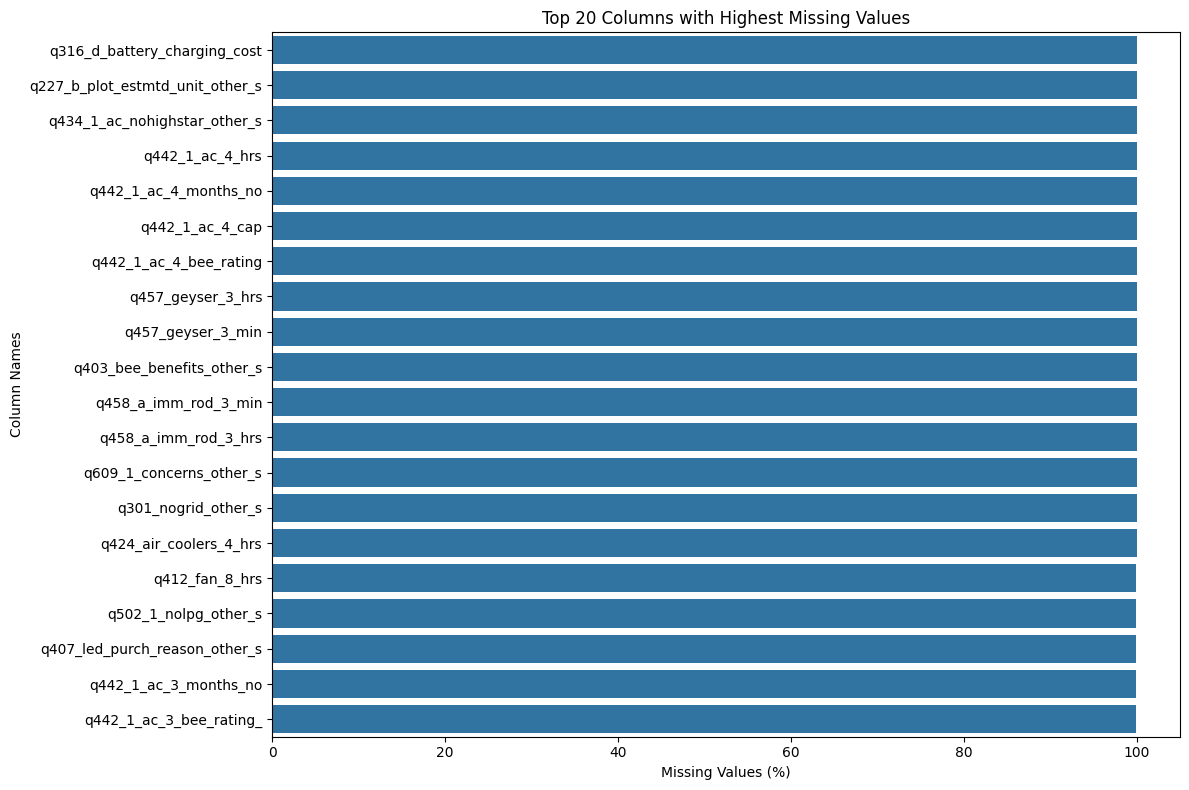

In [15]:

# Visualising top 20 columns with missing values

top_missing = missing_analysis.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_missing["Missing_Percentage"],
    y=top_missing.index
)

plt.title("Top 20 Columns with Highest Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Names")

plt.tight_layout()
plt.show()


Important Project Columns – Missing Value Analysis

In [16]:

# Selecting important columns for our project

important_columns = [
    "s_name",
    "q301_grid_yn",
    "q302_grid_hrs_no",
    "avg_monthly_bill",
    "q409_ceiling_fan_yn",
    "q427_ac_yn",
    "q610_c_billed_amount"
]

# Checking whether all selected columns exist
available_columns = [
    col for col in important_columns if col in df.columns
]

# Creating a missing-value summary
important_missing = pd.DataFrame({
    "Data_Type": df[available_columns].dtypes,
    "Missing_Count": df[available_columns].isnull().sum(),
    "Missing_Percentage": (
        df[available_columns].isnull().sum() / len(df)
    ) * 100,
    "Unique_Values": df[available_columns].nunique()
})

print("Important Project Columns Analysis:")

display(important_missing)


Important Project Columns Analysis:


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
s_name,object,0,0.000000,21
q301_grid_yn,int64,0,0.000000,3
q302_grid_hrs_no,float64,509,3.427379,19
avg_monthly_bill,float64,5083,34.226651,837
q409_ceiling_fan_yn,float64,443,2.982964,2
q427_ac_yn,float64,455,3.063767,2
q610_c_billed_amount,float64,10469,70.493569,1930


Categorical Value Analysis

In [17]:

# Analysing categorical responses

categorical_columns = [
    "q301_grid_yn",
    "q409_ceiling_fan_yn",
    "q427_ac_yn"
]

for col in categorical_columns:

    print("\nColumn:", col)

    print("Value counts:")

    display(df[col].value_counts(dropna=False).to_frame("Count"))



Column: q301_grid_yn
Value counts:


,Count
q301_grid_yn,
1,14342
0,455
2,54



Column: q409_ceiling_fan_yn
Value counts:


,Count
q409_ceiling_fan_yn,
1.0,12954
0.0,1454
NaN,443



Column: q427_ac_yn
Value counts:


,Count
q427_ac_yn,
0.0,13927
1.0,469
NaN,455


Numerical Column Analysis

In [18]:

# Analysing numerical project columns

numerical_columns = [
    "q302_grid_hrs_no",
    "avg_monthly_bill",
    "q610_c_billed_amount"
]

display(df[numerical_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
q302_grid_hrs_no,14342.0,20.546507,4.063426,6.0,18.00000,22.00000,24.0000,24.000
avg_monthly_bill,9768.0,720.046615,738.580565,0.0,223.33333,483.33334,1000.0000,12333.333
q610_c_billed_amount,4382.0,1596.149445,5190.082913,-5222.0,260.00000,600.00000,1389.7175,196944.000


Numerical Anomaly Investigation

In [19]:

# Investigating negative values in numerical columns

numerical_check = [
    "q302_grid_hrs_no",
    "avg_monthly_bill",
    "q610_c_billed_amount"
]

for col in numerical_check:

    print("\nColumn:", col)

    print("Negative values:", (df[col] < 0).sum())

    print("Zero values:", (df[col] == 0).sum())

    print("Missing values:", df[col].isnull().sum())



Column: q302_grid_hrs_no
Negative values: 0
Zero values: 0
Missing values: 509

Column: avg_monthly_bill
Negative values: 0
Zero values: 299
Missing values: 5083

Column: q610_c_billed_amount
Negative values: 22
Zero values: 93
Missing values: 10469


Investigation of Negative Billed Amounts

In [20]:

# Inspecting negative billed amounts

negative_bills = df[df["q610_c_billed_amount"] < 0]

print("Total negative billed amounts:",
      len(negative_bills))

print("\nNegative billed amount values:")

display(
    negative_bills[
        ["hhid", "s_name", "avg_monthly_bill",
         "q610_c_billed_amount"]
    ]
)


Total negative billed amounts: 22

Negative billed amount values:


,hhid,s_name,avg_monthly_bill,q610_c_billed_amount
975,345607450,Telangana,300.000000,-105.00
1279,346040454,Andhra Pradesh,466.666660,-1362.00
1880,346789424,Andhra Pradesh,NaN,-828.00
1892,346040736,Andhra Pradesh,600.000000,-911.00
2523,346040734,Andhra Pradesh,NaN,-443.00
2817,346789428,Andhra Pradesh,783.333310,-250.00
2939,3440792174,Madhya Pradesh,716.666690,-76.56
3488,34678958,Andhra Pradesh,96.666664,-3908.00
4638,346789411,Andhra Pradesh,633.333310,-1065.00
4962,34678959,Andhra Pradesh,93.333336,-5222.00


Investigate extreme values using IQR

In [21]:

# Detecting potential outliers using IQR

for col in numerical_check:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Potential outliers:", len(outliers))



Column: q302_grid_hrs_no
Lower limit: 9.0
Upper limit: 33.0
Potential outliers: 135

Column: avg_monthly_bill
Lower limit: -941.67
Upper limit: 2165.0
Potential outliers: 441

Column: q610_c_billed_amount
Lower limit: -1434.58
Upper limit: 3084.29
Potential outliers: 424


# Data Transformation and Cleaning

1. Selecting Relevant Project Columns

In [22]:

# Creating a separate working dataset

project_columns = [
    "hhid",
    "s_name",
    "d_name",
    "q301_grid_yn",
    "q302_grid_hrs_no",
    "avg_monthly_bill",
    "q409_ceiling_fan_yn",
    "q427_ac_yn",
    "q610_c_billed_amount"
]

# Creating a separate DataFrame
energy_df = df[project_columns].copy()

print("Project dataset created successfully!")

print("Original dataset shape:", df.shape)
print("Project dataset shape:", energy_df.shape)

display(energy_df.head())


Project dataset created successfully!
Original dataset shape: (14851, 517)
Project dataset shape: (14851, 9)


,hhid,s_name,d_name,q301_grid_yn,q302_grid_hrs_no,avg_monthly_bill,q409_ceiling_fan_yn,q427_ac_yn,q610_c_billed_amount
0,343937810,Odisha,PURI,1,22.0,126.66666,0.0,0.0,NaN
1,3444379112,Rajasthan,BARMER,1,24.0,466.66666,0.0,0.0,NaN
2,344869428,Jharkhand,LOHARDAGA,1,15.0,0.00000,0.0,0.0,NaN
3,344393847,Haryana,PANCHKULA,0,NaN,NaN,NaN,NaN,NaN
4,352717410,Uttar Pradesh,SITAPUR,0,NaN,NaN,NaN,NaN,NaN


Verify the selected columns

In [23]:

# Checking the selected project dataset

print("Number of rows:", energy_df.shape[0])
print("Number of columns:", energy_df.shape[1])

print("\nData types:")
print(energy_df.dtypes)

print("\nMissing values:")
print(energy_df.isnull().sum())

print("\nDuplicate rows:")
print(energy_df.duplicated().sum())


Number of rows: 14851
Number of columns: 9

Data types:
hhid                      int64
s_name                   object
d_name                   object
q301_grid_yn              int64
q302_grid_hrs_no        float64
avg_monthly_bill        float64
q409_ceiling_fan_yn     float64
q427_ac_yn              float64
q610_c_billed_amount    float64
dtype: object

Missing values:
hhid                        0
s_name                      0
d_name                      0
q301_grid_yn                0
q302_grid_hrs_no          509
avg_monthly_bill         5083
q409_ceiling_fan_yn       443
q427_ac_yn                455
q610_c_billed_amount    10469
dtype: int64

Duplicate rows:
0


# Transformation - Handle duplicate records

2. Duplicate Record Validation

In [24]:

# Checking duplicate records in the working dataset

duplicate_count = energy_df.duplicated().sum()

print("Duplicate records before cleaning:", duplicate_count)

# Removing duplicate records if present
energy_df = energy_df.drop_duplicates()

print("Duplicate records after cleaning:",
      energy_df.duplicated().sum())

print("Updated dataset shape:", energy_df.shape)


Duplicate records before cleaning: 0
Duplicate records after cleaning: 0
Updated dataset shape: (14851, 9)


# Transformation — Standardise text columns



Our dataset has two text columns:
- s_name — State name
- d_name — District name
We can standardise their formatting by removing unnecessary spaces and applying consistent capitalisation.

3. Standardising Text Columns

This helps avoid inconsistent text entries such as "ODISHA", "Odisha" and " Odisha ".

In [25]:

# Standardising text columns

text_columns = ["s_name", "d_name"]

for col in text_columns:

    energy_df[col] = (
        energy_df[col]
        .astype("string")
        .str.strip()
        .str.title()
    )

print("Text columns standardised successfully!")

display(energy_df[["s_name", "d_name"]].head())


Text columns standardised successfully!


,s_name,d_name
0,Odisha,Puri
1,Rajasthan,Barmer
2,Jharkhand,Lohardaga
3,Haryana,Panchkula
4,Uttar Pradesh,Sitapur


Verify unique state and district names

In [26]:
# Checking unique state and district names

print("Number of Unique States:",
      energy_df["s_name"].nunique())

print("Number of Unique Districts:",
      energy_df["d_name"].nunique())

print("\nUnique State Names:")
print(sorted(energy_df["s_name"].dropna().unique()))

Number of Unique States: 21
Number of Unique Districts: 151

Unique State Names:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


# Initial Data Quality Report
## CEEW – India Residential Energy Survey (IRES 2020)

### 1. Dataset Overview

The CEEW – India Residential Energy Survey (IRES 2020) dataset was inspected to understand its structure and assess its initial data quality.

| Description | Result |
|---|---:|
| Total records (rows) | 14,851 |
| Total attributes (columns) | 517 |
| Dataset size in memory | Approximately 58.6 MB |

### 2. Missing Value Analysis

Missing values were identified and counted across all dataset columns.

| Description | Result |
|---|---:|
| Total missing cells | 4,027,943 |
| Columns containing missing values | 443 |
| Percentage of missing cells | Approximately 52.46% |

**Observation:** A considerable number of missing values were found. These may be associated with survey responses or conditional survey questions. Further investigation is required before deciding how to handle them.

### 3. Duplicate Record Analysis

Duplicate records were checked using pandas.

| Description | Result |
|---|---:|
| Duplicate rows found | 0 |
| Duplicate rows after validation | 0 |

**Observation:** No completely duplicated records were identified in the original dataset.

### 4. Column Names and Data Types

The column names were inspected, and the data types were identified using pandas.

| Data Type | Number of Columns |
|---|---:|
| float64 | 425 |
| int64 | 61 |
| object | 31 |
| **Total** | **517** |

**Observation:** Most columns contain numerical data, while the remaining columns contain integer and object-type values.

### 5. Additional Data Quality Observations

The following additional checks were performed:

- 10 columns contain only one distinct non-missing value.
- 390 columns have 10 or fewer unique non-missing values.
- Potential numerical outliers were identified using the Interquartile Range (IQR) method.
- Negative values were found in some billed-amount records and require further investigation.

Outliers and negative values were not automatically removed because they may represent genuine survey or billing situations.

### 6. Conclusion

The initial data quality assessment identified the structure, missing values, duplicate records, column names and data types of the CEEW – IRES 2020 dataset.

The dataset contains 14,851 records and 517 columns, with a considerable proportion of missing values. No duplicate rows were detected.

These findings provide an initial understanding of the dataset and help identify areas that may require attention during subsequent data preprocessing and transformation stages.

**Status:** Initial Data Quality Analysis Completed.